---
---

# DS-3002 Data Mining - Assignment 04


**Fatima Tu Zahra**

**23i-2616**

**BDS-6B**

**Spring-2026**

---
---


# Imports


In [21]:
!pip install tensorflow


In [22]:
import pandas as pd
import numpy as np
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.spatial.distance import cdist
from tslearn.metrics import dtw

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
from sklearn.tree import _tree
from sklearn.model_selection import cross_validate
from tensorflow.keras.datasets import mnist
import zipfile
import os
import urllib.request






## Scenario

CardioAI Labs is a fictional health-tech startup building decision-support tools for cardiologists at community hospitals. The clinic environment is intentionally constrained: no dedicated data team, ordinary office hardware, and a requirement that models train in minutes, not hours.

The project covers four technical areas:

- **Unsupervised learning** to discover hidden patient subgroups before labels are used.
- **Bagging and boosting** to build robust ensemble classifiers for heart disease prediction.
- **ANN / SLP / MLP** models for tabular heart disease data.
- **CNN** models for handwritten digit recognition on a MNIST subset.
- **Local front-end** dashboard for the best heart disease model.



## Datasets

### Dataset 1: UCI Heart Disease (Cleveland subset) - used in Pre, A, B, C, and E

| Field | Detail |
|---|---|
| Name | Heart Disease Dataset (Cleveland subset) |
| Source | UCI Machine Learning Repository |
| Direct URL | https://archive.ics.uci.edu/dataset/45/heart+disease |
| File to use | processed.cleveland.data |
| Size | 303 rows x 14 columns (13 features + 1 target) |
| Task | Binary classification: heart disease absent (0) vs present (1) |
| Load time | Under 1 second |
| Why it matters | Standard clinical ML benchmark with interpretable cardiology features |

**Feature reference**

| Column | Type | Description |
|---|---|---|
| age | Numeric | Age in years |
| sex | Binary | 1 = male, 0 = female |
| cp | Categorical (0-3) | Chest pain type |
| trestbps | Numeric | Resting blood pressure (mmHg) |
| chol | Numeric | Serum cholesterol (mg/dl) |
| fbs | Binary | Fasting blood sugar > 120 mg/dl |
| restecg | Categorical (0-2) | Resting ECG results |
| thalach | Numeric | Maximum heart rate achieved |
| exang | Binary | Exercise-induced angina |
| oldpeak | Numeric | ST depression induced by exercise relative to rest |
| slope | Categorical (0-2) | Slope of peak exercise ST segment |
| ca | Numeric (0-3) | Number of major vessels coloured by fluoroscopy |
| thal | Categorical (1-3) | Thalassemia |
| target | Binary | 0 = no disease, 1 = disease present |



### Dataset 2: MNIST handwritten digits - used only in Part D

| Field | Detail |
|---|---|
| Name | MNIST Handwritten Digits |
| Load method | tensorflow.keras.datasets.mnist |
| Full size | 70,000 images (60k train + 10k test), 28 x 28 grayscale |
| Subset to use | First 12,000 training images and 2,000 test images |
| Task | 10-class digit classification (0-9) |
| RAM usage | About 15 MB for the subset |


In [23]:
# load mnist from tensorflow
(X_train, y_train), (X_test, y_test) = mnist.load_data()
print("MNIST dataset loaded successfully")

MNIST dataset loaded successfully



## Required Preprocessing - 12 Marks

All preprocessing applies to the Heart Disease dataset unless stated otherwise.

1. Load the CSV and confirm the shape is 303 x 14. Print the first 5 rows and the data types of all columns.


In [24]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
heart_disease = fetch_ucirepo(id=45) 
  
# data (as pandas dataframes) 
X = heart_disease.data.features 
y = heart_disease.data.targets 
y

,num
0,0
1,2
2,1
3,0
4,0
...,...
298,1
299,2
300,3
301,1


In [25]:

# concat the two into one df
df = pd.concat([X, y], axis=1)
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0,2
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0,3
301,57,0,2,130,236,0,2,174,0,0.0,2,1.0,3.0,1


2. Replace the UCI missing-value marker `?` with NaN, report affected columns and row counts, then drop rows with remaining missing values and report the final row count.


In [26]:
# replace ? with NaN
df.replace('?', np.nan, inplace=True)
# now drop missing values
df.dropna(inplace=True)
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,57,0,4,140,241,0,0,123,1,0.2,2,0.0,7.0,1
298,45,1,1,110,264,0,0,132,0,1.2,2,0.0,7.0,1
299,68,1,4,144,193,1,0,141,0,3.4,2,2.0,7.0,2
300,57,1,4,130,131,0,0,115,1,1.2,2,1.0,7.0,3


3. Report the class distribution of the target column, including counts and percentages. State whether the dataset is balanced and justify whether you use SMOTE or class weighting. Apply the chosen approach on the training split only.


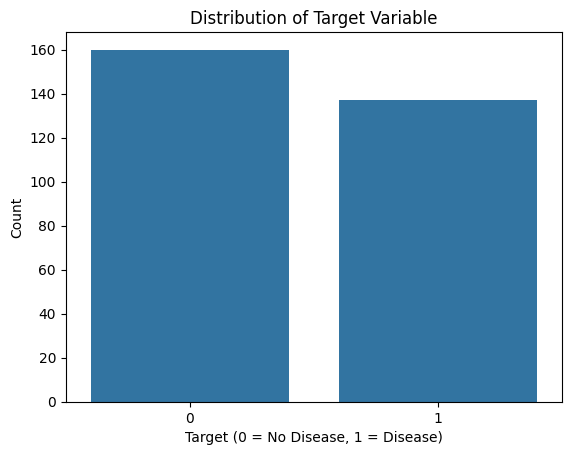

In [27]:
# rename the num column to target
df.rename(columns={'num': 'target'}, inplace=True)
# replace all values greater than 0 in target with 1 (indicating presence of disease)
df['target'] = df['target'].apply(lambda x: 1 if x > 0 else 0)
# distribution of target variable
sns.countplot(x='target', data=df)
plt.title('Distribution of Target Variable')
plt.xlabel('Target (0 = No Disease, 1 = Disease)')
plt.ylabel('Count')
plt.show()

4. One-hot encode the categorical columns `cp`, `restecg`, `slope`, and `thal`


In [29]:
# One-hot encode the categorical columns
categorical_cols = ['cp', 'restecg', 'slope', 'thal']
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
df.head()

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,target,cp_2,cp_3,cp_4,restecg_1,restecg_2,slope_2,slope_3,thal_6.0,thal_7.0
0,63,1,145,233,1,150,0,2.3,0.0,0,False,False,False,False,True,False,True,True,False
1,67,1,160,286,0,108,1,1.5,3.0,1,False,False,True,False,True,True,False,False,False
2,67,1,120,229,0,129,1,2.6,2.0,1,False,False,True,False,True,True,False,False,True
3,37,1,130,250,0,187,0,3.5,0.0,0,False,True,False,False,False,False,True,False,False
4,41,0,130,204,0,172,0,1.4,0.0,0,True,False,False,False,True,False,False,False,False



5. Create a stratified 80/20 train/test split with `random_state=42`. Reuse this exact split for Parts A, B, C, and E


In [31]:
# train/test split
X = df.drop('target', axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)


6. Standardize the continuous columns `age`, `trestbps`, `chol`, `thalach`, `oldpeak`, and `ca`, fitting the scaler on the training set only


In [32]:
# standardize the columns age, trestbps, chol, thalach, oldpeak, and ca in the Xtrain
scaler = StandardScaler()
continuous_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'ca']
X_train[continuous_cols] = scaler.fit_transform(X_train[continuous_cols])
X_train

,age,sex,trestbps,chol,fbs,thalach,exang,oldpeak,ca,cp_2,cp_3,cp_4,restecg_1,restecg_2,slope_2,slope_3,thal_6.0,thal_7.0
55,-0.085668,1,-0.462582,0.312737,0,-1.827448,1,0.967117,0.349404,False,False,True,False,True,True,False,False,True
160,-0.973247,1,-1.749078,-0.987921,1,0.275439,0,-0.901878,-0.740185,True,False,False,False,False,False,False,False,True
178,-1.306090,1,-0.126974,1.236393,0,0.543892,0,0.712254,0.349404,False,True,False,False,False,False,False,False,False
86,-0.862300,1,0.320503,0.143086,0,0.275439,0,-0.901878,-0.740185,False,True,False,False,True,False,False,False,False
79,0.358121,1,0.991719,0.388137,0,-1.737964,1,-0.222243,-0.740185,False,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9,-0.196616,1,0.432372,-0.874820,1,0.230696,1,1.731706,-0.740185,False,False,True,False,True,False,True,False,True
213,1.245701,0,2.557888,-0.403568,1,0.678119,1,-0.052335,1.438993,False,False,True,False,False,True,False,False,True
294,0.912858,0,-0.462582,-0.987921,0,-0.619407,1,-0.901878,-0.740185,False,False,True,False,False,True,False,False,False
184,0.580016,0,1.439196,1.047892,0,0.499150,0,-0.901878,-0.740185,False,False,True,False,True,False,False,False,False



7. Produce a correlation heatmap of the original numeric features. Identify the three strongest feature pairs and briefly note whether any could affect Naive Bayes assumptions.


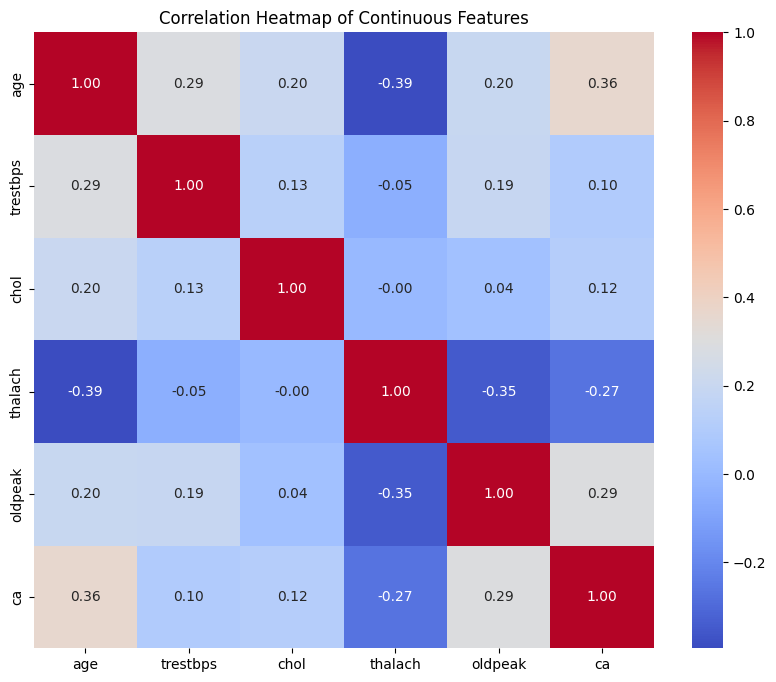

In [33]:
correlation_matrix = df[continuous_cols].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap of Continuous Features')
plt.show()


## Part A: Unsupervised Learning - 20 Marks

Use the standardized feature matrix without the target label.



### A1. K-Means Clustering - 8 Marks

- Run K-Means for `k` in {2, 3, 4, 5, 6, 7, 8} on the full standardized feature matrix.
- For each `k`, record inertia and silhouette score.
- Plot both curves on one figure with two y-axes.
- Mark the chosen `k` and justify it in 2-3 sentences.
- Reduce the matrix to 2D with PCA and plot side-by-side scatter plots coloured by K-Means cluster labels and true disease labels.
- For each cluster in the chosen `k`, report cluster size, disease proportion, and mean values for `thalach`, `oldpeak`, and `cp`.
- Compute ARI between cluster assignments and true labels, then interpret the score.



### A2. Hierarchical Clustering - 7 Marks

- Compute Ward linkage on the standardized feature matrix.
- Plot a dendrogram truncated to the top 25 merges.
- Annotate the recommended cut height and resulting cluster count.
- Cut the tree at the chosen level and show a cluster-vs-label crosstab.
- Compare hierarchical clustering and K-Means using ARI between the two clusterings, not against the labels.
- Discuss which method you trust more for clinical segmentation and why.



### A3. Dimensionality Reduction - 5 Marks

- Apply PCA and plot component-wise explained variance plus cumulative variance.
- Report how many components are needed for 90% explained variance.
- Apply t-SNE with `n_components=2`, `perplexity=30`, and `random_state=42`.
- Plot the embedding coloured by the true disease label.
- Briefly discuss whether the classes appear separable in t-SNE space.



## Part B: Bagging and Boosting - 22 Marks

Use the same 80/20 stratified split. Report accuracy, macro precision, recall, F1, AUC-ROC, and a confusion matrix for each sub-part.



### B1. Random Forest - 8 Marks

- Tune `n_estimators` in {50, 100, 200} and `max_depth` in {None, 5, 10} using 5-fold cross-validation on the training set.
- Report the best combination and its mean CV F1.
- Plot OOB error versus number of trees from 1 to 200.
- Mark the point where OOB error stabilizes and compare it with the chosen `n_estimators`.
- Plot feature importances as a horizontal bar chart.
- List the top 5 features and explain why each is clinically plausible.
- Report the evaluation metrics and confusion matrix.
- Discuss which class has worse recall and the consequence of false negatives in a screening setting.



### B2. Gradient Boosting - 9 Marks

Choose either XGBoost or LightGBM and state your choice.

- Tune `learning_rate` in {0.01, 0.1, 0.3} and `max_depth` in {3, 5, 7} using 5-fold CV.
- Report the best configuration and CV F1.
- Train the final model with early stopping patience of 50 rounds.
- Plot training and validation log-loss per boosting round and mark the optimal round.
- Discuss any signs of overfitting.
- Compute SHAP values for the test set and interpret the top contributors.
- Report the evaluation metrics and confusion matrix.



### B3. Ensemble Comparison and ROC - 5 Marks

- Complete the comparison table with your actual results.
- Plot overlapping ROC curves for the best A3 classifier, Random Forest, and XGBoost or LightGBM.
- Label each curve with the classifier name and AUC value.
- Write a 4-5 sentence recommendation for deployment in a community hospital screening pipeline.
- Justify why recall matters more than overall accuracy in this context.



## Part C: Artificial Neural Networks on Tabular Data - 20 Marks

Use the same Heart Disease dataset and 80/20 split. Implement the models in TensorFlow/Keras or PyTorch.



### C1. Single-Layer Perceptron - 5 Marks

- Build a model with one output neuron and sigmoid activation, with no hidden layers.
- Train with binary cross-entropy and SGD using `lr=0.01` for 100 epochs.
- Plot training loss and training accuracy versus epoch.
- Inspect the learned input weights and identify the top 3 by absolute value.
- Compare this ranking with Random Forest feature importances.
- Report accuracy, F1, AUC, and confusion matrix.
- Discuss why a linear model is limited for this problem.



### C2. Multi-Layer Perceptron - 10 Marks

Experiment with at least three architectures.

| Architecture | Hidden Layers | Val F1 | Notes |
|---|---|---|---|
| Small | 1 layer: 32 units | - | Baseline |
| Medium | 2 layers: 64 -> 32 | - | Add regularisation |
| Large | 3 layers: 128 -> 64 -> 32 | - | Add regularisation |
| Optional 4th | Your design | - | - |

For the final MLP, state and justify:

- activation function
- regularisation strategy
- optimiser and learning rate
- number of epochs with EarlyStopping patience 10 on validation loss

Then:

- Plot training and validation loss and accuracy curves.
- Annotate where early stopping triggered.
- Run 5-fold cross-validation on the training set and report mean +/- std accuracy and F1.
- Report all evaluation metrics and the confusion matrix.
- Compare the MLP to the best ensemble from Part B.



### C3. Ablation Study - 5 Marks

Starting from the best MLP, train three reduced variants one change at a time:

- Variant A: remove all Dropout layers.
- Variant B: replace ReLU or LeakyReLU with Sigmoid activations.
- Variant C: remove Early Stopping and train for a fixed 150 epochs.

Record test F1 and validation-loss curves for each variant, then tabulate the best MLP plus the three variants. Discuss which component contributed most to performance.



## Part D: CNN on MNIST Digit Images - 16 Marks



### D1. Data Preparation and Baseline - 5 Marks

- Normalize pixel values to [0, 1].
- Reshape images to `(28, 28, 1)` for Keras or `(1, 28, 28)` for PyTorch.
- Display a 5 x 2 grid of sample images, one per digit class, with correct labels.
- Train a simple fully connected baseline: Flatten -> Dense(64, ReLU) -> Dense(10, Softmax).
- Train for 5 epochs and record test accuracy.



### D2. Lightweight CNN - 7 Marks

Build the following architecture, with small justified modifications if needed:

- Conv2D(16, kernel 3x3, ReLU, same padding)
- MaxPooling2D(2x2)
- Conv2D(32, kernel 3x3, ReLU, same padding)
- MaxPooling2D(2x2)
- Flatten
- Dense(64, ReLU)
- Dropout(0.3)
- Dense(10, Softmax)

Also:

- Apply data augmentation.
- Train with Adam at `lr=0.001` and categorical cross-entropy.
- Plot training and validation accuracy and loss.
- Report test accuracy, macro F1, and a confusion-matrix heatmap.
- Identify the two digit pairs most often confused.
- Compare CNN accuracy with the MLP baseline and note how many epochs the CNN needs to surpass it.



### D3. Visualising What the CNN Learned - 4 Marks

- Display the 16 learned filters from the first Conv2D layer as a 4 x 4 grid.
- For one test image per digit class, display the first 8 feature-map channels from the first Conv2D layer as a 2 x 4 grid.
- Describe what the filters and feature maps appear to detect.
- Explain how these visualisations help build trust and how they differ from fully connected models.



## Part E: Local Front-End Dashboard - 10 Marks

Build a simple interactive front-end that runs locally. The grader should be able to launch it with a single command.



### E1. Input Form - 4 Marks

- Display 13 labeled input fields, one per feature, each with a brief valid-range hint.
- Include a clearly labelled Predict button.
- Pre-populate the form with values from one real test patient so graders can run a prediction immediately.



### E2. Results Panel - 4 Marks

On prediction, display:

- the predicted class with a colour-coded risk label
- the model confidence score as a percentage
- the top 3 driving features as a small horizontal bar chart using SHAP or feature importances
- a brief plain-English explanation a nurse can read and act on



### E3. Submission - 2 Marks

Include in your ZIP:

- `app.py` or equivalent
- the saved model file
- `requirements.txt`

In the report, include at least two screenshots of the running app: one for the input form and one for the prediction result.



## GitHub Integration - Bonus up to 5 Marks

| Criterion | What We Check | Marks |
|---|---|---|
| G1 - Repo structure | README.md plus `/notebooks`, `/app`, and `/report` folders | 1 |
| G2 - Commit history | At least 8 commits across at least 3 different calendar days | 2 |
| G3 - Reproducibility | `requirements.txt` or `environment.yml` | 1 |
| G4 - Notebook runs clean | Restarting the kernel and running all cells produces the reported results | 1 |

## Grading Summary

| Part / Section | Marks |
|---|---|
| Preprocessing and Data Setup | 12 |
| A - Unsupervised Learning | 20 |
| B - Bagging and Boosting | 22 |
| C - ANN / SLP / MLP + Ablation | 20 |
| D - CNN on MNIST Digits | 16 |
| E - Local Front-End Dashboard | 10 |
| GitHub Integration Bonus | up to +5 |
| TOTAL | 100 (+5 bonus) |

## Resources and Libraries

| Task | Library / Command |
|---|---|
| Clustering | `sklearn.cluster.KMeans`, `AgglomerativeClustering`, `scipy.cluster.hierarchy.dendrogram` |
| Dimensionality reduction | `sklearn.decomposition.PCA`, `sklearn.manifold.TSNE` |
| Imbalanced data | `imblearn.over_sampling.SMOTE` |
| Random Forest | `sklearn.ensemble.RandomForestClassifier` |
| Gradient Boosting | `xgboost.XGBClassifier` or `lightgbm.LGBMClassifier` |
| SHAP | `shap` |
| Neural networks | `tensorflow.keras` or `torch` + `torch.nn` |
| MNIST loading | `tensorflow.keras.datasets.mnist` |
| CNN visualization | First-layer filters and feature maps |
| Front-end | `streamlit` |
| Evaluation | `sklearn.metrics` |
| Model saving | `joblib` or `keras model.save` |

## Key References

- UCI Heart Disease: Detrano, R. et al. (1989)
- Random Forests: Breiman, L. (2001)
- XGBoost: Chen, T. and Guestrin, C. (2016)
- SHAP: Lundberg, S. M. and Lee, S. I. (2017)
- LeNet / CNN foundations: LeCun, Y. et al. (1998)
- t-SNE: van der Maaten, L. and Hinton, G. (2008)

Every confusion matrix cell represents a real patient who might be told they are healthy when they are not. Build models you can explain, run experiments you can reproduce, and write interpretations a cardiologist could trust.

Good luck - and happy mining.
